# Across animals analysis

In [2]:
from multimodal_analysis.db import get_schema_modules

exp, stim, beh, inter, rec, mice = get_schema_modules()

from multimodal_analysis.config import (
    create_analysis_key,
    get_behavior_sessions,
    plot_behavior_task_types,
)
from multimodal_analysis.plots import (
    plot_modalities_across_animals_scatter,
    plot_modalities_across_animals_line,
)

Please enter DataJoint username:  eflab
Please enter DataJoint password:  ········


[2026-10-18 02:09:16,151][INFO]: Connecting eflab@database.eflab.org:3306
[2026-10-18 02:09:16,305][INFO]: Connected eflab@database.eflab.org:3306


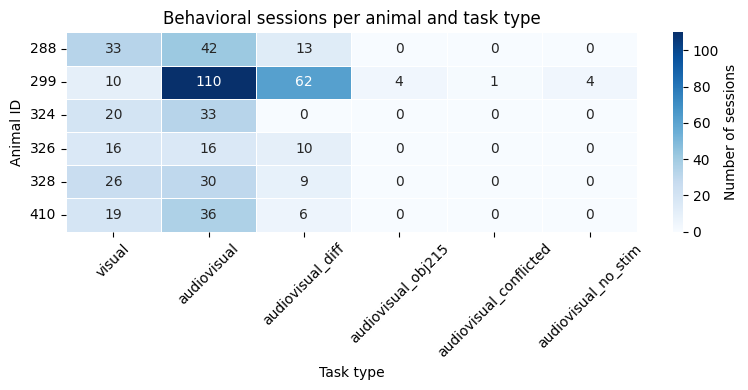

In [3]:
# Plot behavioral task types across animals.
# Parameter:
# show_counts (bool): If True, display the number of sessions per task type.
task_type_across_animals = plot_behavior_task_types(show_counts=True)

In [36]:
# Define the animal and behavioral task for the analysis
# Set animal_id to None to include all animals
# Available task types: "visual", "audiovisual", "audiovisual_diff", "audiovisual_no_stim", 
# "audiovisual_obj215", "audiovisual_conflicted"
animal_id = 299
task_type = "audiovisual"

# Define the difficulty levels and sessions to exclude.
difficulties = [2]
excluded_sessions = []

In [41]:
# Get the behavioral sessions available for the selected animal and task.
sessions_idx = get_behavior_sessions(animal_id=animal_id, task_type=task_type)
print("sessions_idx: \n", sessions_idx)

# Define the first session to include in the analysis.
from_session = get_behavior_sessions(animal_id=animal_id, task_type=task_type)[0]
print("\nfrom_session:", from_session)

# Define the last session to include in the analysis.
to_session = get_behavior_sessions(animal_id=animal_id, task_type=task_type)[-75]
print("to_session:", to_session)

# Calculate the total number of sessions included in the analysis.
total_sessions = sum(from_session <= session <= to_session for session in sessions_idx)
print("total_sessions:", total_sessions)

sessions_idx: 
 [100, 103, 107, 111, 113, 117, 119, 121, 123, 125, 129, 131, 133, 135, 137, 139, 194, 196, 197, 198, 199, 200, 202, 203, 204, 205, 206, 207, 210, 211, 213, 323, 324, 326, 331, 333, 334, 335, 336, 337, 338, 340, 341, 342, 343, 346, 352, 359, 360, 361, 362, 363, 374, 376, 379, 380, 381, 383, 385, 386, 388, 390, 465, 473, 474, 475, 486, 488, 489, 490, 491, 492, 493, 478, 481, 486, 488, 489, 490, 491, 492, 493, 578, 583, 584, 585, 586, 589, 590, 593, 595, 596, 597, 598, 600, 601, 603, 604, 605, 606, 607, 608, 609, 611, 615, 624, 626, 627, 631, 633]

from_session: 100
to_session: 333
total_sessions: 36


In [42]:
animal_configs = {
    299: {
        "from_session": 100,
        "to_session": 333,
        "difficulties": [2],
        "excluded_sessions": [],
    },
    288: {
        "from_session": 184,
        "to_session": 369,
        "difficulties": [2],
        "excluded_sessions": [],
    },
    324: {
        "from_session": 47,
        "to_session": 93,
        "difficulties": [2],
        "excluded_sessions": [],
    },
    326: {
        "from_session": 57,
        "to_session": 100,
        "difficulties": [2],
        "excluded_sessions": [],
    },
    328: {
        "from_session": 105,
        "to_session": 165,
        "difficulties": [2],
        "excluded_sessions": [],
    },
    410: {
        "from_session": 135,
        "to_session": 196,
        "difficulties": [2],
        "excluded_sessions": [],
    },
}

keys = [
    create_analysis_key(
        animal_id=animal_id,
        from_session=config["from_session"],
        to_session=config["to_session"],
        difficulties=config["difficulties"],
        excluded_sessions=config["excluded_sessions"],
    )
    for animal_id, config in animal_configs.items()
]

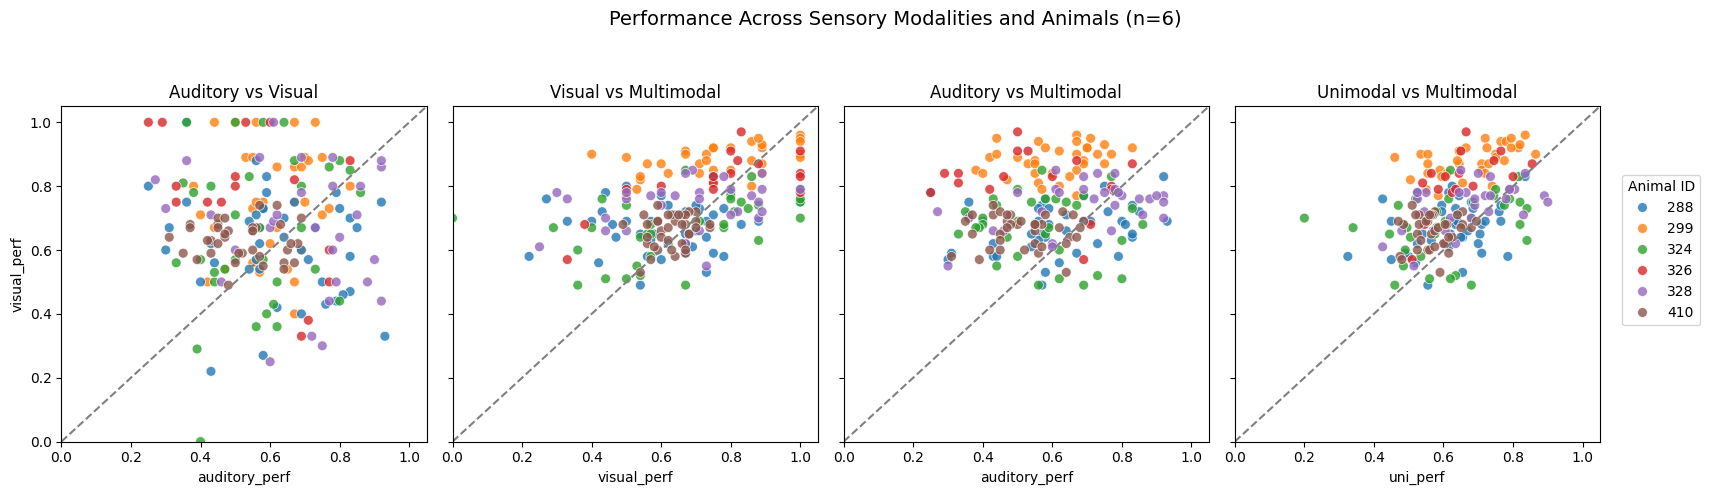

<Axes: title={'center': 'Unimodal vs Multimodal'}, xlabel='uni_perf', ylabel='multi_perf'>

In [59]:
plot_modalities_across_animals_scatter(keys, stim, exp)